Cortes calculados:
B: 0.0 47.0
G: 0.0 49.0
R: 0.0 53.0


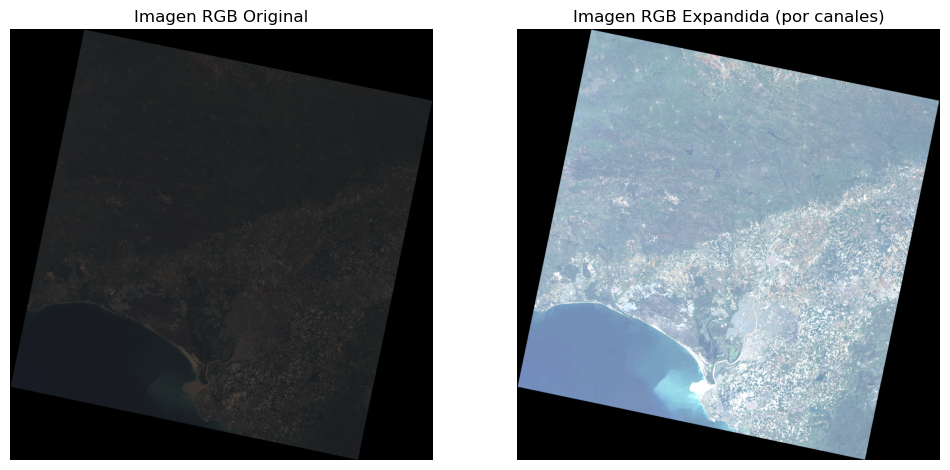

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def expan(img, cmin, cmax):
    salida = np.zeros_like(img, dtype=np.uint8)
    filas, cols = img.shape
    for i in range(filas):
        for j in range(cols):
            ND = img[i, j]
            if ND <= cmin:
                salida[i, j] = 0
            elif ND >= cmax:
                salida[i, j] = 255
            else:
                salida[i, j] = int(((ND - cmin) * 255) / (cmax - cmin))
    return salida

b = cv2.imread("RGB/Landsat_C_02-11_B.png", cv2.IMREAD_GRAYSCALE)
g = cv2.imread("RGB/Landsat_C_03-11_G.png", cv2.IMREAD_GRAYSCALE)
r = cv2.imread("RGB/Landsat_C_04-11_R.png", cv2.IMREAD_GRAYSCALE)

def get_cuts(img, pmin=2, pmax=98):
    return np.percentile(img, pmin), np.percentile(img, pmax) #Para hacer una elección sin ojímetro

cmin_b, cmax_b = get_cuts(b)
cmin_g, cmax_g = get_cuts(g)
cmin_r, cmax_r = get_cuts(r)

print("Cortes calculados:")
print("B:", cmin_b, cmax_b)
print("G:", cmin_g, cmax_g)
print("R:", cmin_r, cmax_r)

b_exp = expan(b, cmin_b, cmax_b)
g_exp = expan(g, cmin_g, cmax_g)
r_exp = expan(r, cmin_r, cmax_r)

img_rgb_orig = cv2.merge([b, g, r])
img_rgb_exp  = cv2.merge([b_exp, g_exp, r_exp])

plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img_rgb_orig, cv2.COLOR_BGR2RGB))
plt.title("Imagen RGB Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(img_rgb_exp, cv2.COLOR_BGR2RGB))
plt.title("Imagen RGB Expandida (por canales)")
plt.axis("off")
plt.show()
